In [7]:
import matplotlib.pyplot as plt  # 导入 matplotlib 库，用于图像显示
from PIL import Image  # 导入 PIL 库，用于图像加载和处理
import torchvision.transforms as transforms  # 导入 torchvision.transforms 模块，用于图像预处理

In [8]:
# 定义图像转换操作
transform = transforms.Compose([
    transforms.Resize((256, 256)),  # 调整图像大小为 256x256
    transforms.ToTensor(),  # 将图像转换为 PyTorch 张量
])

# 加载 JPG 图像
img_path = 'Apple.jpg'  # 图像文件路径，替换为你的图像路径
image = Image.open(img_path)  # 使用 PIL 打开图像

# 应用定义的转换操作
img_tensor = transform(image)  # 将图像转换为张量并调整大小
print(img_tensor.shape)  # 打印张量的形状，格式为 (C, H, W)


torch.Size([3, 256, 256])


In [9]:
# 将张量转换为 NumPy 数组
img_numpy = img_tensor.numpy()  # 将 PyTorch 张量转换为 NumPy 数组，形状为 (C, H, W)

# 将张量转换为 NumPy 数组
img_numpy = img_tensor.numpy()  # 将 PyTorch 张量转换为 NumPy 数组，形状为 (C, H, W)

# PoTorch 的图像张量使用 (C, H, W) 格式，而 Matplotlib 的图像显示函数需要 (H, W, C) 格式的数组，需要转换维度
# 调整 NumPy 数组的维度顺序
img_numpy = img_numpy.transpose(
    (1, 2, 0))  # 将形状从 (C, H, W) 转换为 (H, W, C)，transpose 中的参数 (1, 2, 0) 并不是具体的数据数值，而是原数组的“维度索引（轴序号）”

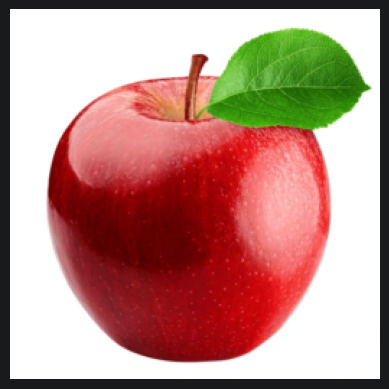

In [10]:
# 显示图像
plt.imshow(img_numpy)  # 显示调整后的 NumPy 数组
plt.axis('off')  # 不显示坐标轴
plt.show()  # 显示图像

# 普通卷积
计算公式：
    $$H_{out} = \lfloor \frac{H_{in} + 2 \times \text{padding} - \text{kernel\_size}}{\text{stride}} \rfloor + 1$$

已知 $H_{in} = 256$，$K=3, S=1, P=1$，带入公式：
    $$H_{out} = \lfloor \frac{256 + 2 \times 1 - 3}{1} \rfloor + 1 = \lfloor \frac{255}{1} \rfloor + 1 = 256$$

设计目的：
- 保留原始图像尺寸（Same Padding）：卷积核设为 $3 \times 3$ 时，边缘补一圈像素（padding=1），再以步长 $1$ 滑动，输出图像尺寸与输入保持完全一致。
- 这样设计是为了把“图像缩小的任务”明确解耦交给 nn.MaxPool2d(2, 2)，让卷积层只专注于特征提取。

# 转置卷积
计算公式
    $$H_{out} = (H_{in} - 1) \times \text{stride} - 2 \times \text{padding} + \text{kernel\_size} + \text{output\_padding}$$

已知输入特征尺寸 $H_{in} = 64$（经过编码器两次池化后的尺寸），设 $K=3, S=2, P=1, OP=1$，带入公式：
    $$H_{out} = (64 - 1) \times 2 - 2 \times 1 + 3 + 1 = 126 - 2 + 3 + 1 = 128$$



In [14]:
import torch  # 导入 PyTorch 库
import torch.nn as nn  # 导入 PyTorch 的神经网络模块
import torch.optim as optim  # 导入 PyTorch 的优化器模块


# 定义自编码器（Autoencoder）的架构
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()  # 调用父类的构造函数，初始化模型

        # 编码器部分：将输入图像压缩为低维特征表示
        self.encoder = nn.Sequential(
            # 第一层卷积：输入通道数为 3（RGB 图像），输出通道数为 16，卷积核大小为 3x3，步长为 1，填充为 1
            # 输出尺寸：(16, 256, 256), H_in = 256, H_out = 256
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            # 为什么中间隐藏层偏爱用 ReLU？ ReLU 的数学公式非常简单：$f(x) = \max(0, x)$。 隐藏层用 ReLU：负责高效地提取复杂特征，不需要限制数值上下限。
            # 1. 解决梯度消失问题（支持深层网络）
            # 传统的 Sigmoid 或 Tanh 函数在输入值很大或很小时，函数曲线会趋于平缓，导数（梯度）接近 0。层数一多，前向传导的梯度相乘后就会“消失”，导致前面几层权重根本学不到东西。
            # ReLU 在 $x > 0$ 时导数恒为 1，反向传播时梯度能毫无损耗地传回前面的层。
            # 2. 计算速度极快
            # Sigmoid 和 Tanh 涉及复杂指数运算（$e^{-x}$），在大型矩阵运算中非常耗时。
            # ReLU 只需要判断数值是否大于 0，计算开销几乎为零，大幅加速模型训练。
            # 3. 产生稀疏激活（Sparse Activation）
            # $x < 0$ 时，ReLU 的输出直接置为 0。这意味着在任意时刻，网络中只有一部分神经元被“激活”。这种稀疏性不仅节省计算量，还能提取出更鲁棒、更具代表性的特征（类似人类大脑对特定刺激只有部分区域兴奋）。
            nn.ReLU(),  # ReLU 激活函数，引入非线性
            # 最大池化层：池化核大小为 2x2，步长为 2，将图像尺寸减半
            nn.MaxPool2d(kernel_size=2, stride=2),
            # 第二层卷积：输入通道数为 16，输出通道数为 8，卷积核大小为 3x3，步长为 1，填充为 1
            nn.Conv2d(16, 8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),  # ReLU 激活函数
            # 最大池化层：池化核大小为 2x2，步长为 2，将图像尺寸再次减半
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # 解码器部分：将低维特征表示重构为原始图像
        self.decoder = nn.Sequential(
            # 第一层转置卷积：输入通道数为 8，输出通道数为 16，卷积核大小为 3x3，步长为 2，填充为 1，输出填充为 1
            nn.ConvTranspose2d(8, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),  # ReLU 激活函数
            # 第二层转置卷积：输入通道数为 16，输出通道数为 3，卷积核大小为 3x3，步长为 2，填充为 1，输出填充为 1
            nn.ConvTranspose2d(16, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
            # 输出层用 Sigmoid：因为目标是重建 RGB 图像。归一化后的图像像素值严格限制在 $[0, 1]$。如果输出层用 ReLU，网络可能会输出 $>1$ 的无意义大数或负数，导致无法正常渲染像素。
            nn.Sigmoid()  # Sigmoid 激活函数，将输出值限制在 [0, 1] 范围内，表示像素值
        )

    def forward(self, x):
        x = self.encoder(x)  # 对输入图像进行编码
        # print("encode shape: ", x.shape)
        x = self.decoder(x)  # 对编码后的特征进行解码，重构图像
        # print("decode shape: ", x.shape)
        return x


# 初始化自编码器模型
model = Autoencoder()

# 测试模型前向传播
x = model.forward(torch.randn(1, 3, 256, 256))

| 损失函数     | PyTorch 类名        | 适合场景               | 特点                                         |
| ------------ | ------------------- | ---------------------- | -------------------------------------------- |
| 均方误差     | nn.MSELoss          | 图像重构、数值回归     | 计算像素/数值差值的平方，对大误差惩罚极重    |
| 平均绝对误差 | nn.L1Loss           | 图像超分辨率、去噪     | 计算差值的绝对值，对离群点不敏感，边缘更清晰 |
| 二分类交叉熵 | nn.BCELoss          | 二分类、二值化图像重构 | 配合 Sigmoid，衡量概率分布的相似度           |
| 多分类交叉熵 | nn.CrossEntropyLoss | 图像分类、文本生成     | 内部自动做 Softmax，衡量类别预测准确度       |

| 优化器                   | 特点                                                                                                                                                                                                                                      | 优缺点                                                                                                                                            | 适用场景                                                                                                                          |
| ------------------------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------- |
| SGD (随机梯度下降)       | 最经典的优化器。每次更新移动固定步长。每次迭代只使用一个样本进行参数更新                                                                                                                                                                  | 优点：计算效率高，适合大规模数据集；缺点：收敛速度较慢，容易卡在局部极小值或鞍点；对学习率极其敏感。                                              | 大型图像分类模型（如 ResNet）训练后期，搭配动量（Momentum）和衰减策略，最终泛化能力往往比 Adam 略好。适用于大规模数据集和在线学习 |
| RMSprop                  | 增加了自适应学习率机制，根据历史梯度的波动幅度自动调整每个参数的更新步长。适合处理非平稳目标的优化器。通过对梯度平方的指数加权平均来调整学习率                                                                                            | 优点：适合处理非平稳目标，收敛速度快；缺点：可能会导致过拟合，需要调节学习率和衰减参数。                                                          | 适用于循环神经网络（RNN）和长短期记忆网络（LSTM）等序列模型训练，尤其是在处理时间序列数据时表现良好。                             |
| Adam（自适应矩估计）     | SGD 动量机制 + RMSprop 自适应学习率 的集大成者。它既考虑了前几次更新的方向（惯性），又会为更新频繁的参数降低学习率、为更新稀疏的参数提高学习率。结合了动量和RMSprop的优点，使用一阶矩估计和二阶矩估计来调整学习率。适合大多数深度学习任务 | 优点：极度鲁棒，基本不需要精心调参，默认学习率 $0.001$ 就能在绝大多数任务上快速收敛。收敛速度快，适应性强；缺点：可能会导致过拟合，对超参数敏感。 | 广泛应用于各种深度学习任务，如图像分类、自然语言处理等，尤其在训练复杂模型时表现良好。                                            |
| AdamW（权重衰减的 Adam） | 在 Adam 的基础上引入了权重衰减（Weight Decay）机制，解决了 Adam 在某些情况下可能导致过拟合的问题。通过在更新参数时直接应用权重衰减，而不是将其作为正则化项添加到损失函数中                                                                | 优点：在训练深度神经网络时能够有效防止过拟合，收敛速度快；缺点：需要调节权重衰减参数，可能增加训练复杂性。                                        | 适用于需要正则化的深度学习任务，如图像分类、目标检测等，尤其在大规模数据集上表现良好。                                            |


In [15]:
# 将模型移动到 GPU（如果可用），否则使用 CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)  # 打印当前使用的设备（GPU 或 CPU）
model.to(device)  # 将模型参数和缓冲区移动到指定设备

# 定义损失函数和优化器
criterion = nn.MSELoss()  # 使用均方误差损失（MSE），衡量重构图像与原始图像的差异
optimizer = optim.Adam(model.parameters(), lr=0.001)  # 使用 Adam 优化器，学习率为 0.001

# 训练自编码器
num_epochs = 400  # 训练的总轮数
for epoch in range(num_epochs):
    img = img_tensor.to(device)  # 将输入图像移动到指定设备
    optimizer.zero_grad()  # 清空梯度缓存，避免梯度累积
    output = model(img)  # 前向传播，获取重构图像
    loss = criterion(output, img)  # 计算损失（重构图像与原始图像的差异）
    loss.backward()  # 反向传播，计算梯度
    optimizer.step()  # 更新模型参数
    if epoch % 50 == 0:  # 每 50 轮打印一次损失值
        print('Epoch [{}/{}], Loss: {:.4f}'.format(epoch + 1, num_epochs, loss.item()))

# 保存训练好的模型
torch.save(model.state_dict(), 'conv_autoencoder.pth')


cuda
Epoch [1/400], Loss: 0.1784
Epoch [51/400], Loss: 0.0969
Epoch [101/400], Loss: 0.0321
Epoch [151/400], Loss: 0.0185
Epoch [201/400], Loss: 0.0142
Epoch [251/400], Loss: 0.0110
Epoch [301/400], Loss: 0.0077
Epoch [351/400], Loss: 0.0047


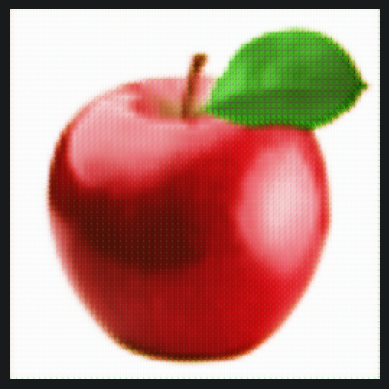

In [16]:
# 推理阶段不需要梯度计算
# 禁用梯度计算，减少内存消耗并加速推理过程
with torch.no_grad():
    # 将图像张量移动到指定设备（GPU 或 CPU）
    data = img_tensor.to(device)
    # 使用训练好的模型对输入数据进行重构，得到输出张量
    recon = model(data)

# 导入 Matplotlib 库，用于图像显示
import matplotlib.pyplot as plt

# 显示重构后的图像
# 1. 将张量从 GPU 移到 CPU（如果张量在 GPU 上）
# 2. 转换为 NumPy 数组
# 3. 调整维度顺序从 (C, H, W) 到 (H, W, C)，以适配 Matplotlib 的 imshow 函数
plt.imshow(recon.cpu().numpy().transpose((1, 2, 0)))

# 关闭坐标轴显示，使图像更干净
plt.axis('OFF')

# 渲染并显示图像窗口
plt.show()
